# 07 – Almanac player cards (2025-26)

**Almanac** is Project 1: what happened in a single season. This notebook builds the first player cards, Baseball Savant style.

- **Percentiles** compare each player to **qualified players at the same position** (forwards vs. forwards, defensemen vs. defensemen). Qualified = 200+ minutes at 5v5. Players below that still get a card, drawn faint.
- **Colors:** red = better, blue = worse, gray = style stats (hits, blocks) that describe how he plays rather than how good he is. Notebook 05 showed hits and blocks are consistent but not tied to winning.
- **Skating and shot speed** come from NHL EDGE, live from the NHL's public API. Those percentiles are the NHL's own.
- **Clutch** has a placeholder for v1.1.

The code lives in `src/player_card.py`, so any player's card is one line.

Data: MoneyPuck.com (`data/skaters25-26.csv`) and NHL EDGE.

## 1. Setup

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from war_model import run_season, V04_PARAMS
from player_card import build_metrics, add_percentiles, fetch_edge, draw_card, SECTIONS

DATA = Path("../data")
CARDS = Path("../images/cards")
CARDS.mkdir(parents=True, exist_ok=True)

SEASON_FILE = DATA / "skaters25-26.csv"
SEASON_LABEL = "2025-26"
SEASON_CODE = "20252026"   # NHL API season format

## 2. Percentile table
Run v0.4 WAR, add every card stat, then rank each player within his position.

In [2]:
war = run_season(SEASON_FILE, V04_PARAMS)
cards = add_percentiles(build_metrics(war, SEASON_FILE))

print("Skaters:", len(cards), "| qualified (200+ 5v5 min):", int(cards["qualified"].sum()))
print(cards.groupby("pos_group")["qualified"].sum().rename("qualified by position"))

Skaters: 940 | qualified (200+ 5v5 min): 719
pos_group
D    250
F    469
Name: qualified by position, dtype: int64


In [3]:
pct_cols = [c for c in cards.columns if c.startswith("pct_")]
keep = ["playerId", "name", "team", "position", "pos_group", "games_played", "ev_toi", "qualified",
        "war", "war_rank", "war_rank_pos"] + [c[4:] for c in pct_cols] + pct_cols
cards[keep].to_csv(DATA / "percentiles_2025-26.csv", index=False)
print("Saved data/percentiles_2025-26.csv")

Saved data/percentiles_2025-26.csv


### Sanity check: top 10 defensemen by WAR
The leaders should be defensemen widely seen as excellent this season.

In [4]:
(cards[cards["pos_group"] == "D"].nsmallest(10, "war_rank_pos")
     [["name", "team", "war", "pct_war", "off_war", "pct_off_war", "def_war", "pct_def_war"]].round(2))

,name,team,war,pct_war,off_war,pct_off_war,def_war,pct_def_war
497,Zach Werenski,CBJ,3.91,100.0,3.37,100.0,0.15,73.0
202,Rasmus Dahlin,BUF,3.87,99.0,3.11,98.0,0.65,98.0
822,Cale Makar,COL,3.59,99.0,3.34,99.0,-0.40,21.0
462,Lane Hutson,MTL,3.31,99.0,1.78,93.0,1.04,99.0
920,Jakob Chychrun,WSH,3.20,98.0,3.15,99.0,0.02,58.0
621,Evan Bouchard,EDM,3.18,98.0,3.17,99.0,-0.41,19.0
308,Josh Morrissey,WPG,3.13,97.0,2.29,97.0,0.61,97.0
485,Matthew Schaefer,NYI,3.06,97.0,2.05,94.0,0.16,75.0
788,Moritz Seider,DET,2.97,97.0,1.17,87.0,1.64,100.0
623,Jake Sanderson,OTT,2.74,96.0,2.01,93.0,0.26,83.0


## 3. Moritz Seider

In [5]:
seider = cards[cards["name"] == "Moritz Seider"].iloc[0]
edge = fetch_edge(seider["playerId"], SEASON_CODE)
edge

{'top_speed': (21.7169, 51.849999999999994),
 'bursts_20': (43.0, 74.38),
 'shot_speed': (98.93, 92.88),
 'oz_pct': (0.43579397, 79.11111111111)}

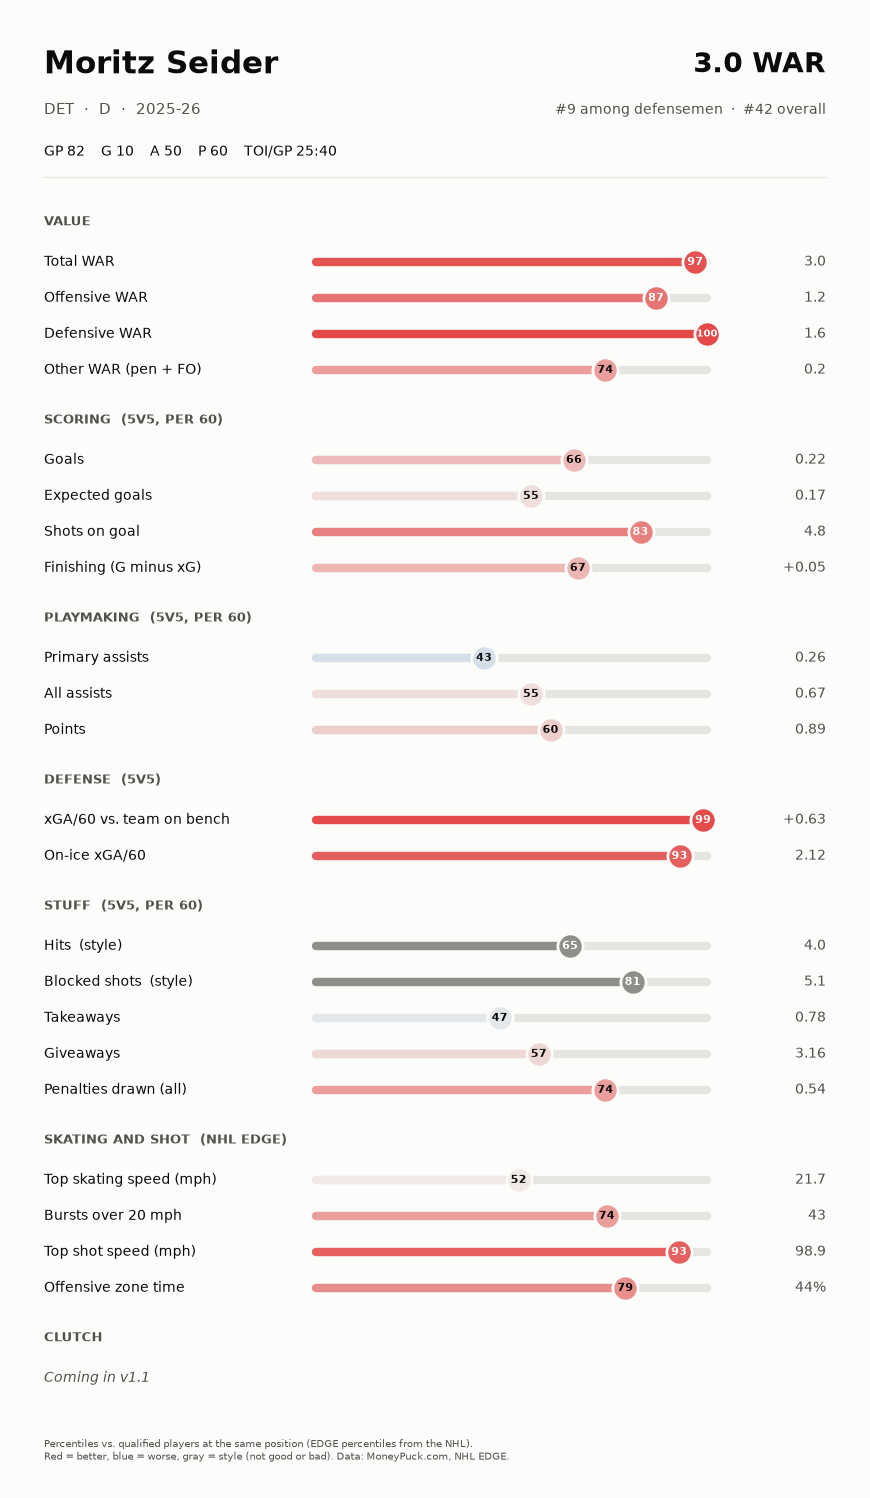

In [6]:
fig = draw_card(seider, SEASON_LABEL, edge, CARDS / "seider_2025-26.png")
plt.show()

## 4. Any player
Change the name and run the cell.

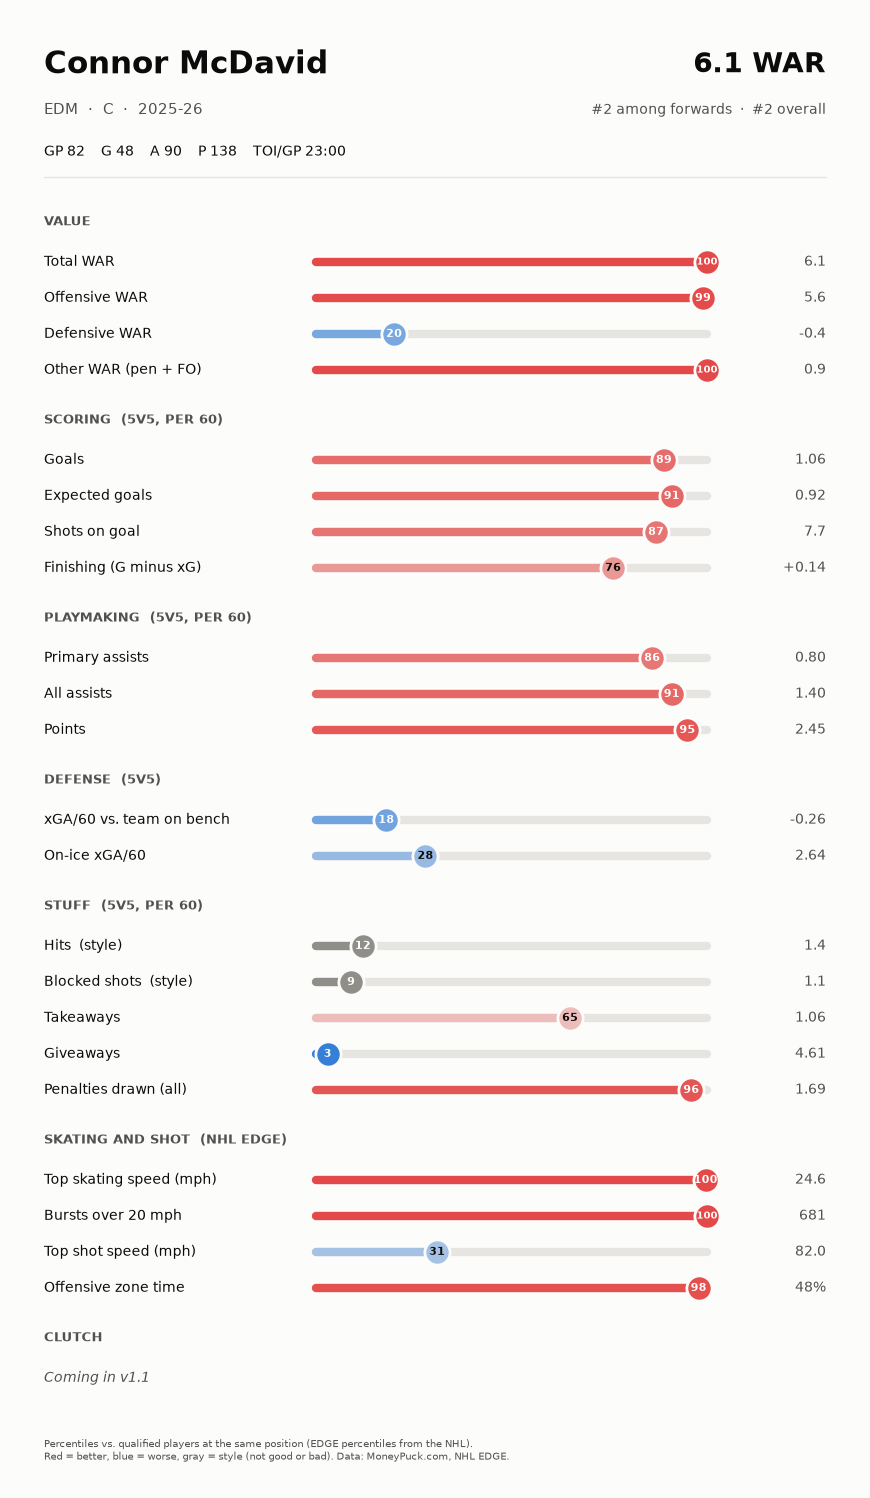

In [7]:
def card(name):
    match = cards[cards["name"] == name]
    if match.empty:
        print("No player named", name, "| close matches:", cards[cards["name"].str.contains(name.split()[-1], case=False)]["name"].tolist())
        return
    player = match.iloc[0]
    fig = draw_card(player, SEASON_LABEL, fetch_edge(player["playerId"], SEASON_CODE))
    plt.show()

card("Connor McDavid")

## Notes
- **Per 60 at 5v5** for the scoring, playmaking, defense, and stuff rows, so ice time and power play time don't drive the percentiles. Power play value is already inside Offensive WAR.
- **Season totals** (GP, G, A, P) in the header are all situations.
- **Next:** check the cards against hockey knowledge for 10 to 15 players, then put them in a Streamlit app with a player search.